# Roshan's Data 11/20/26

Roshan has sent me two text files of data. I think that they are just on the center line and are the B fields in mT.

Let's look at the first few lines of a file. 
NOTE that this the first few lines of the downstream file and I analyze the upstream file in what is below so the numbers won't match!

Well that looks like something that I can read with numpy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
updata = np.loadtxt('upstream_center.txt', skiprows=1)

In [3]:
updata.shape

(948, 5)

Very believable. 

OK, so I think that what we are dealing with is a set of data at different positions and with different probe orientations. Let's look at the data for that first position. There are 12 rows at 30° angular increments. 

In [4]:
angs = updata[:12, 1] * 30

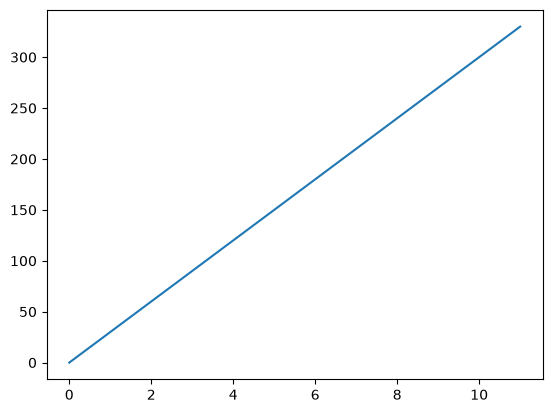

In [5]:
plt.plot(angs)

Well that looks sensible. But WHAT a pity we don't go all the way to 360°.

Let's look at the B values, removing the average Bz.

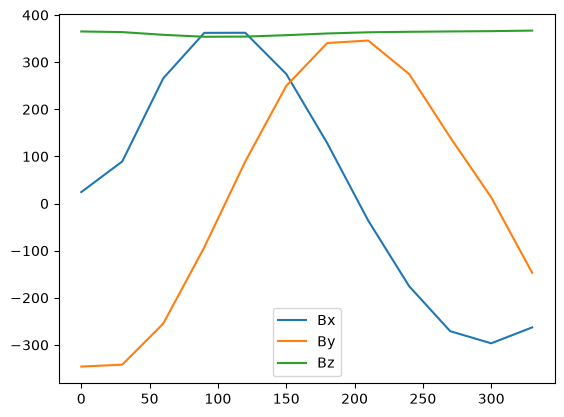

In [6]:
names = [ 'Posn (m)', 'Angle', 'Bx', 'By', 'Bz']
updata1 = updata[:12, :].copy()
updata1[:, 4] -= 1774
for i in range(2,5):
    plt.plot(angs, updata1[:, i], label=names[i])
plt.legend()

Well that looks like a slightly mis-oriented probe. I studied mis-oriented probes a long time ago. What did I learn?

Well, apparently I learned to lose it. That means I have to reconstruct it. The idea is that we figure out the field components measured by a probe set that is slightly mis-oriented relative to the rotation axis (the actual z axis). We have to consider effects due to mis-orientation of the probe set and mis-orientation of the actual field and we have to see if we can sort out both from a set of rotational data.

We start with a fixed coordinate frame S in which everything is embedded. In that frame there is a field $\vec{B}$ with components $\left( B_x, B_y, B_z \right)$ and I will be assuming, at least initially, that $|B_z|>>|Bx|,|B_y|$.

We also have a sensor trio. For simplicity we will assume that the three sensors are properly orthogonal but that the z measurement axis of the sensor is oriented at some small angle $\theta_0$ to the fixed z axis. We will further assume that when the sensor is in its canonical orientation, the sensor axis set is also rotated a small angle $\phi_0$ relative to the fixed x axis. To be specific, the sensor frame is first rotated an angle $\phi_0$ about the z axis and then rotated through an angle $\theta_0$ about the y axis. Given that we can find the components in frame S of the unit vectors in frame S'.

The matrix that rotates through an angle $\phi_0$ about the z axis is $R_{z,\phi_0}$
$$R_{z,\phi_0} = \begin{bmatrix}
 \cos\phi_0 & \sin\phi_0 & 0 \\
 -\sin\phi_0 & \cos\phi_0 & 0 \\
 0 & 0 & 1
\end{bmatrix}$$

The matrix that rotates through an angle $\theta_0$ about the y axis is $R_{y,\theta_0}$
$$R_{y,\theta_0} = \begin{bmatrix}
 \cos\theta_0 & 0 & -\sin\theta_0 \\
 0 & 1 & 0 \\
 \sin\theta_0 & 0 & \cos\theta_0 
\end{bmatrix}$$

This means that the matrix that rotates first about z and then about y is
$$\begin{bmatrix}
 \cos\theta_0 & 0 & -\sin\theta_0 \\
 0 & 1 & 0 \\
 \sin\theta_0 & 0 & \cos\theta_0 
\end{bmatrix} * 
\begin{bmatrix}
 \cos\phi_0 & \sin\phi_0 & 0 \\
 -\sin\phi_0 & \cos\phi_0 & 0 \\
 0 & 0 & 1
\end{bmatrix} = \begin{bmatrix}
 \cos\theta_0\cos\phi_0 & \cos\theta_0\sin\phi_0 & -\sin\theta_0 \\
 -\sin\theta_0 & \cos\theta_0 & 0 \\
 \sin\theta_0\cos\phi_0 & \sin\theta_0\sin\phi_0 & \cos\theta_0 
\end{bmatrix}$$

So applying that in turn to the unit vectors in S gives us the S-frame components of the S' unit vectors, which I am calling $\left( \hat{M}_x, \hat{M}_y, \hat{M}_z \right)$, so that
$$\hat{M}_x = \begin{pmatrix} \cos\theta_0\cos\phi_0 \\ -\sin\theta_0 \\ \sin\theta_0\cos\phi_0 \end{pmatrix}$$
$$\hat{M}_y = \begin{pmatrix} \cos\theta_0\sin\phi_0 \\ \cos\theta_0 \\ 0 \end{pmatrix}$$
$$\hat{M}_z = \begin{pmatrix} -\sin\theta_0 \\ _0 \\ \cos\theta_0 \end{pmatrix}$$


## A single measurement

A measurement consists of taking the dot product between each of the sensor vectors and the local field vector. So, in the initial position we measure components $\left( B'_x, B'_y, B'_z \right)$ where
$$B'_x = \vec{\hat{M}_x} \cdot{} \vec{B} = B_x \cos\theta_0\cos\phi_0 - B_y \sin\theta_0 + B_z \sin\theta_0\cos\phi_0$$
$$B'_y = \vec{\hat{M}_x} \cdot{} \vec{B} = -B_x \cos\theta_0\sin\phi_0 + B_y \cos\theta_0$$
$$B'_z = \vec{\hat{M}_x} \cdot{} \vec{B} = B_x \sin\theta_0\cos\phi_0 + B_y \sin\theta_0\sin\phi_0 + B_z \cos\theta_0$$


If you look at those under the assumptions that $B_x$, $B_y$, $\theta_0$, and $\phi_0$ are all small then you find that $B'_z$ and $B'_y$ are both small while $B'_z$ is nearly equal to $B_z$, as we expect.

## A Rotation Sequence

Now we look at what happens when we rotate the probe through various angles about the S-frame z axis. If we call the rotation angle $\psi$ then we already know that the appropriate rotation matrix is $R_{z,\psi}$ given by
$$R_{z,\psi} = \begin{bmatrix}
 \cos\psi & \sin\psi & 0 \\
 -\sin\psi & \cos\psi & 0 \\
 0 & 0 & 1
\end{bmatrix}$$

We can find the rotated $\hat{M}$ vectors by multiplying with the combined $R_{z,\psi}R_{y, \theta_0}R_{z, \phi_0}$ matrix
$$R_{z,\psi}R_{y, \theta_0}R_{z, \phi_0}=
\begin{bmatrix}
 \cos\psi & \sin\psi & 0 \\
 -\sin\psi & \cos\psi & 0 \\
 0 & 0 & 1
\end{bmatrix} *
\begin{bmatrix}
 \cos\theta_0\cos\phi_0 & \cos\theta_0\sin\phi_0 & -\sin\theta_0 \\
 -\sin\theta_0 & \cos\theta_0 & 0 \\
 \sin\theta_0\cos\phi_0 & \sin\theta_0\sin\phi_0 & \cos\theta_0 
\end{bmatrix}$$


$$=\begin{bmatrix}
 \cos\psi\cos\theta_0\cos\phi_0 - \sin\psi\sin\theta_0  & \cos\psi\cos\theta_0\sin\phi_0  + \sin\psi\cos\theta_0 & -\cos\psi\sin\theta_0 \\
 -\sin\psi\cos\theta_0\cos\phi_0 - \cos\psi\sin\theta_0 & -\sin\psi\cos\theta_0\sin\phi_0  + \cos\psi\cos\theta_0 & \sin\psi\sin\theta_0 \\
 \sin\theta_0\cos\phi_0 & \sin\theta_0\sin\phi_0 & \cos\theta_0 
\end{bmatrix}$$

Then things go really wild. Each of the *columns* of this matrix is one of the rotated $\hat{M_{i,\phi}}$ vectors so we have to dot them with the original $\vec{B}$ vector to find the components in this frame.
$$B^"_x = B_x (\cos\psi\cos\theta_0\cos\phi_0 - \sin\psi\sin\theta_0)  + B_y (-\sin\psi\cos\theta_0\cos\phi_0 - \cos\psi\sin\theta_0) + B_z (\sin\theta_0\cos\phi_0)$$
$$B^"_y = -B_x (\cos\psi\cos\theta_0\sin\phi_0  + \sin\psi\cos\theta_0) + B_y (-\sin\psi\cos\theta_0\sin\phi_0  + \cos\psi\cos\theta_0) + B_z (\sin\theta_0\sin\phi_0)$$
$$B^"_z = -B_x \cos\psi\sin\theta_0 + B_y \sin\psi\sin\theta_0 + B_z \cos\theta_0$$

Rewriting to separate the variable $\psi$ from the fixed angles $\theta_0$ and $\phi_0$

$$B^"_x = (B_x \cos\theta_0\cos\phi_0 - B_y \sin\theta_0)\cos\psi - (B_x \sin\theta_0  + B_y \cos\theta_0\cos\phi_0)\sin\psi + B_z \sin\theta_0\cos\phi_0$$
$$B^"_y =  (B_y \cos\theta_0 -B_x \cos\theta_0\sin\phi_0)\cos\psi -(B_x \cos\theta_0 + B_y \cos\theta_0\sin\phi_0)\sin\psi  + B_z \sin\theta_0\sin\phi_0$$
$$B^"_z = -B_x \sin\theta_0\cos\psi + B_y \sin\theta_0\sin\psi + B_z \cos\theta_0$$

So the $B^"_z$ component should have an average value of $B_z \cos\theta_0$ and an oscillating component with magnitude $\sin\theta_0\sqrt{B_x^2 + B_y^2 }$. That seems quite possible given the graph.

The $B^"_x$ and $B^"_y$ graphs should have average values of $B_z \sin\theta_0\cos\phi_0$ and $B_z \sin\theta_0\sin\phi_0$ respectively. We can pull these values (roughly) from the data.

In [7]:
Bx_mean = np.average(updata[:12, 2])
By_mean = np.average(updata[:12, 3])
Bz_mean = np.average(updata[:12, 4])
print(Bx_mean, By_mean, Bz_mean)

38.742200000000004 22.555933333333325 2135.559716666666


So do these tell a consistent story? If we sum the squares of the $B^"_x$ and $B^"_y$ averages then we should get a value for $B_z \sin\theta_0$

In [8]:
Bs0est = np.sqrt(Bx_mean**2 + By_mean**2)
print(Bs0est)

44.82999207425513


Combining that with $B_z \cos\theta_0$ from $B^"_z$ we get and estimate of $B_z$

In [9]:
Bz_est = np.sqrt(Bs0est**2 + Bz_mean**2)
print(Bz_est)

2136.0302038217505


and an estimate for $\theta_0$

In [13]:
t0_est = np.arctan2(Bs0est, Bz_mean)
print(t0_est, t0_est * 180 / np.pi)

0.020989068290352075 1.2025850289490403


A theta of about 1.2 degrees seems reasonable as it is the offset of the internal detector slabs from the housing.

We can get $\psi$ from the ratio of the means of the x and y components. It could be almost anything.

In [14]:
p0_est = np.arctan2(By_mean, Bx_mean)
print(p0_est, p0_est * 180 / np.pi)

0.5272327631089286 30.208212147162335


That all seems believable. Can we come up with values for $B_x$ and $B_y$ too? Well, obviously we can by fitting and it may indeed be time for that. So we need a function of five parameters, Bx, By, Bz, and the two angles that returns three arrays.

I arrange the parameters
$\theta_0$
$\phi_0$
$B_x$
$B_y$
$B_z$


In [65]:
def bmodel(params, angles):
    nangles = len(angles)
    t0 = params[0]
#    print(params, angles)
    st0 = np.sin(t0)
    ct0 = np.cos(t0)
#    print(ct0)
    phi0 = params[1]
    sp0 = np.sin(phi0)
    cp0 = np.cos(phi0)
    bx = params[2]
    by = params[3]
    bz = params[4]
#    print(bx, by, bz)
    probe_vals = np.zeros((nangles, 3))
    for i in range(nangles):
        psi = angles[i] * np.pi / 180
        spsi = np.sin(psi)
        cpsi = np.cos(psi)
        t = (bx * ct0 * cp0 - by * st0) * cpsi
        t -= (bx * st0 + by * ct0 * cp0) * spsi
        probe_vals[i, 0] = t + bz * st0 * cp0
        t = (by * ct0 - bx * ct0 * sp0) * cpsi
        t -= (bx * ct0 + by * ct0 * sp0) * spsi
        probe_vals[i, 1] = t + bz * st0 * sp0
        probe_vals[i, 2] = -bx * st0 * cpsi + by * st0 * spsi + bz * ct0
    return probe_vals


Let's try with something based on our knowledge so far and the guess that $B_x=0$.

In [44]:
ip = [ 0.020989068290352075, 0.5272327631089286, 0, -365, 2136 ]

In [45]:
guess = bmodel(ip, angs)

0.9997797375925478
0 -365 2136


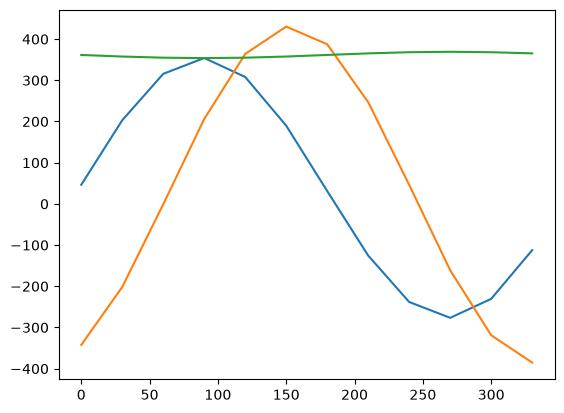

In [47]:
offsets = [0, 0, 1774]
for i in range(3):
    plt.plot(angs, guess[:, i]-offsets[i])

OK! So that is a good starting point. Now can we actually fit it?

In [66]:
def probe_fit(params, *args):
    global pf_init
    data = args[0]
    angs = args[1]
    fit = bmodel(params, angs)
    resids = data - fit
    err = np.sum(resids * resids)
    return err

In [61]:
from scipy.optimize import minimize

In [67]:
fit0 = minimize(probe_fit, ip, args = (updata[:12, 2:], angs))

In [68]:
print(fit0)

  message: Desired error not necessarily achieved due to precision loss.
  success: False
   status: 2
      fun: 68133.98975955888
        x: [ 9.567e-03 -4.828e-01 -5.384e+01 -3.316e+02  2.136e+03]
      nit: 14
      jac: [-5.498e-01  1.172e-02 -9.766e-04 -9.766e-04 -1.953e-03]
 hess_inv: [[ 8.950e-09  6.297e-09 ... -4.716e-06 -2.370e-06]
            [ 6.297e-09  6.810e-07 ...  1.097e-05  5.467e-06]
            ...
            [-4.716e-06  1.097e-05 ...  9.120e-03  4.564e-03]
            [-2.370e-06  5.467e-06 ...  4.564e-03  2.292e-03]]
     nfev: 156
     njev: 26


So the message is likely due to the wide range of parameter values but let's look at the result.

In [69]:
dvals = updata[:12, 2:]
fvals = bmodel(fit0.x, angs)

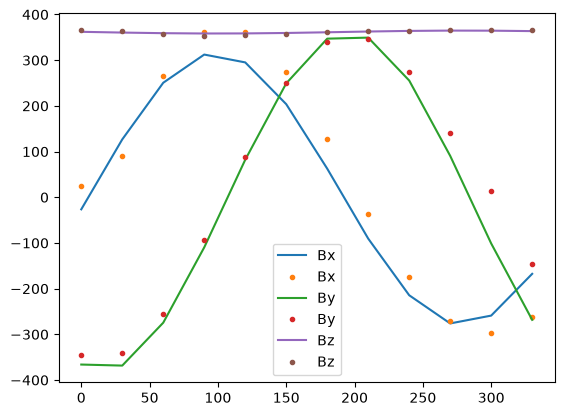

In [71]:
bnames = [ 'Bx', 'By', 'Bz' ]
for i in range(3):
    plt.plot(angs, fvals[:, i]-offsets[i], angs, dvals[:, i]-offsets[i], '.', label=bnames[i])
plt.legend()

Well, the fit to $B_x$ isn't as good as I would like but overall that is pretty impressive. And what did we get for B values?

In [72]:
print('Bx = ', fit0.x[2])
print('By = ', fit0.x[3])
print('Bz = ', fit0.x[4])


Bx =  -53.84148024844538
By =  -331.61968871867936
Bz =  2135.6900883412463


So we see a small but very non-zero Bx despite symmetry. And when we say small we mean 538 Gauss, one thousand times earth's field.

What if we look at the next set of points.

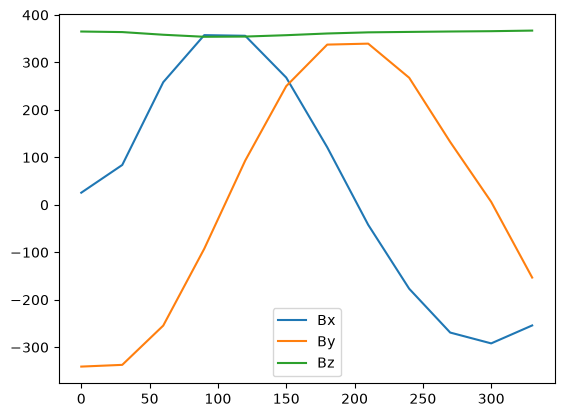

In [74]:
for i in range(3):
    plt.plot(angs, updata[12:24:, i+2]-offsets[i], label=bnames[i])
plt.legend()

Well, as you would expect, rather similar. Lets solve this one using the params from the last one as initial conditions.

In [75]:
fit1 = minimize(probe_fit, fit0.x, args = (updata[12:24, 2:], angs))

In [76]:
print(fit1)

  message: Desired error not necessarily achieved due to precision loss.
  success: False
   status: 2
      fun: 59376.38778677097
        x: [ 9.237e-03 -4.780e-01 -5.379e+01 -3.275e+02  2.136e+03]
      nit: 11
      jac: [-1.465e-03  4.883e-04  4.883e-04  4.883e-04  4.883e-04]
 hess_inv: [[ 9.095e-09  1.091e-08 ...  2.805e-07  1.205e-07]
            [ 1.091e-08  6.875e-07 ... -1.355e-05 -3.399e-06]
            ...
            [ 2.805e-07 -1.355e-05 ...  5.026e-02  1.426e-02]
            [ 1.205e-07 -3.399e-06 ...  1.426e-02  6.423e-02]]
     nfev: 186
     njev: 31


In [77]:
print('Bx = ', fit1.x[2])
print('By = ', fit1.x[3])
print('Bz = ', fit1.x[4])

Bx =  -53.79073806998704
By =  -327.476912273955
Bz =  2135.71713262903


and the angles have shifted a little bit from

In [80]:
print(fit0.x[:2]*180/np.pi, 'degrees')

[  0.54817507 -27.66127681] degrees


to

In [81]:
print(fit1.x[:2]*180/np.pi, 'degrees')

[  0.52924575 -27.38881065] degrees


and I am betting that we could fit both with the same set of angles.

Just for good measure, here is the fit.

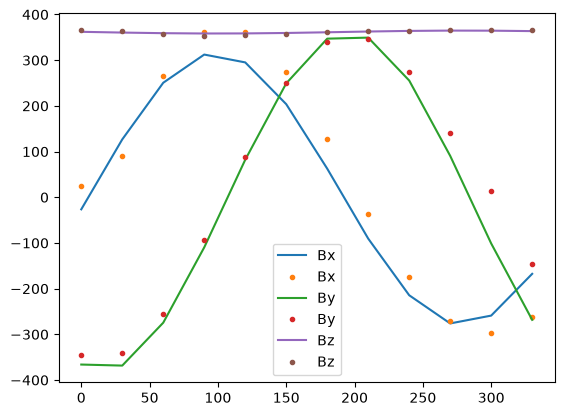

In [82]:
dvals1 = updata[12:24, 2:]
fvals1 = bmodel(fit1.x, angs)
for i in range(3):
    plt.plot(angs, fvals[:, i]-offsets[i], angs, dvals[:, i]-offsets[i], '.', label=bnames[i])
plt.legend()

# Mass fitting

From here it gets a bit more difficult. Now we want to fit all 945 data points. I think that we have all the tools. We just need to make space to store all the results (the parameters) and make sure that we fit each point starting from the previous point.

In [95]:
npoint = int(len(updata[:, 0]) / 12)
fit_params = np.zeros((npoint, 5))
fit_params[0, :] = fit0.x
fits = [ fit0 ]

In [97]:
for i in range(1, npoint-1):
    dat = updata[12 * i:12 * (i+1), 2:]
    new_fit = minimize(probe_fit, fit_params[i-1], args = (dat, angs))
    fits.append(new_fit)
    fit_params[i] = new_fit.x

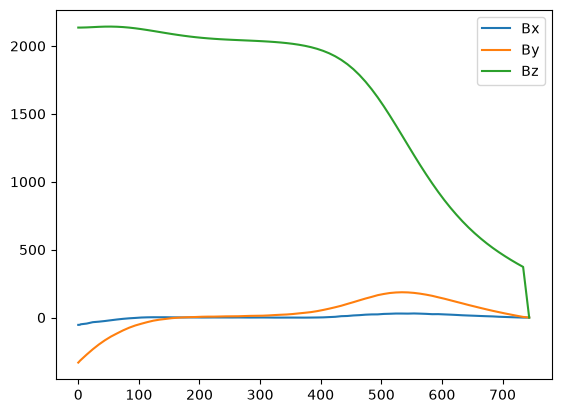

In [99]:
plt.plot(updata[::12, 0], fit_params[:, 2], label='Bx')
plt.plot(updata[::12, 0], fit_params[:, 3], label='By')
plt.plot(updata[::12, 0], fit_params[:, 4], label='Bz')
plt.legend()

I think that the Bx and By are consistent with a constant rotation of the S-frame relative to the actual magnet frame. That could be found by fitting another rotation about z with the goal of minimizing Bx everywhere. It will not affect Bz. We can test this by plotting the ration of By to Bx.

/var/folders/p7/njpc8rfn2hx1blgkj_q6tjvm0000gn/T/ipykernel_67067/1177874695.py:1: RuntimeWarning: invalid value encountered in divide
  plt.plot(updata[::12, 0], fit_params[:, 3] / fit_params[:, 2])


(-50.0, 50.0)

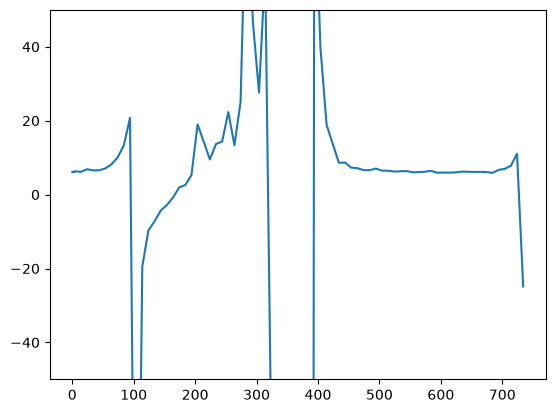

In [102]:
plt.plot(updata[::12, 0], fit_params[:, 3] / fit_params[:, 2])
plt.ylim(-50, 50)

Well, it gets terribly noisy where Bx and By get very small and a real Bx starts to show up above 700 mm but if we look at the ratio near zero and near 500 then we get

In [104]:
print(fit_params[1, 3] / fit_params[1, 2])
print(fit_params[56, 3] / fit_params[56, 2])

6.087979530005246
6.232804757771627


Yes, essentially constant. So we should probably rotate into the Bx=0 orientation.

What about the downstream data?

In [105]:
downdata = np.loadtxt('downstream_center.txt', skiprows=1)
downdata.shape

(1404, 5)

In [106]:
ndpoint = int(downdata.shape[0]/12)
ndpoint

117

Again, we start with the first point.

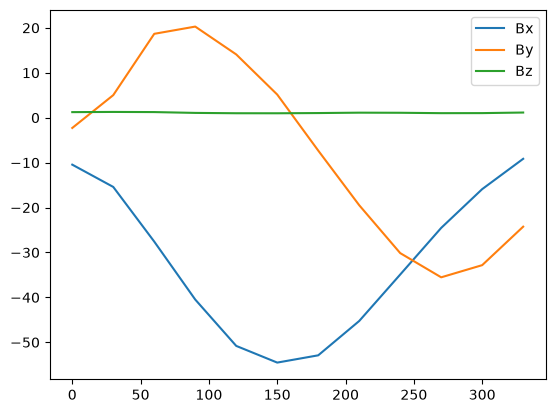

In [110]:
ddata1 = downdata[:12, :].copy()
for i in range(2,5):
    plt.plot(angs, ddata1[:, i]-offsets[i-2], label=names[i])
plt.legend()

Interesting. The Bz trace is MUCH flatter, indicating a much smaller $\theta_0$ value for this direction. This suggests that the tubes are not as exactly axial as we would like to believe!

Let's try fitting.

In [130]:
dp = [fit0.x[0], fit0.x[1], -3, 2, 1774]
fitd0 = minimize(probe_fit, dp, args = (downdata[:12, 2:], angs))
fitd0

  message: Desired error not necessarily achieved due to precision loss.
  success: False
   status: 2
      fun: 7621.954547958431
        x: [-1.841e-02  2.199e-01 -3.444e+00  1.200e+00  1.775e+03]
      nit: 16
      jac: [ 4.810e-02  0.000e+00 -6.104e-05  0.000e+00  0.000e+00]
 hess_inv: [[ 1.427e-08 -8.393e-09 ...  2.399e-06  1.499e-06]
            [-8.393e-09  4.084e-05 ... -6.749e-05  2.785e-05]
            ...
            [ 2.399e-06 -6.749e-05 ...  8.234e-03  7.810e-04]
            [ 1.499e-06  2.785e-05 ...  7.810e-04  1.804e-02]]
     nfev: 156
     njev: 26

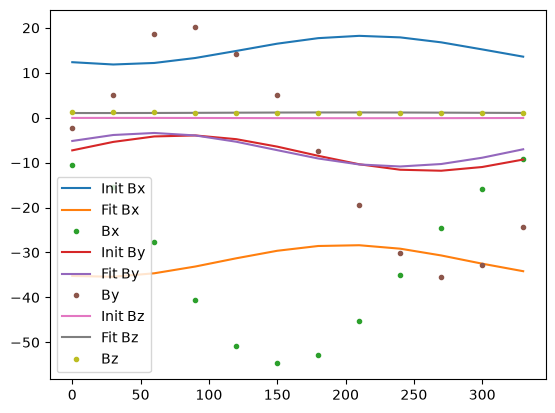

In [131]:
ddvals0 = downdata[:12, 2:]
fdvals0 = bmodel(fitd0.x, angs)
idvals0 = bmodel(dp, angs)
for i in range(3):
    plt.plot(angs, idvals0[:, i]-offsets[i], label=f'Init {bnames[i]}')
    plt.plot(angs, fdvals0[:, i]-offsets[i], label=f'Fit {bnames[i]}') 
    plt.plot(angs, ddvals0[:, i]-offsets[i], '.', label=bnames[i])
plt.legend()

The fitting is doing a terrible job. Either there is a flaw in the model or the serious difference in scaling is screwing with things. I will try playing with scaling. First play with scaling the residuals because Bz is 100x Bx or By.